<a href="https://colab.research.google.com/github/a01841264-cloud/TC5053-ciencia-datos/blob/main/Actividad5Preprocesamiento.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**MAESTRÍA EN INTELIGENCIA ARTIFICIAL APLICADA**

**Curso: TC5053 - Ciencia y analítica de datos**

Tecnológico de Monterrey

Prof Grettel Barceló Alonso

**Semana 5**
Preprocesamiento de datos

---

*   NOMBRE: Roberto Mendoza Monreal
*   MATRÍCULA: A01841264

En esta actividad trabajarás con el archivo `heart_disease.csv`, basado en un conjunto de datos sobre pacientes y variables clínicas relacionadas con enfermedades cardíacas, disponible en Kaggle.

Los datos fueron recopilados para analizar la presencia de enfermedades cardíacas en los pacientes y contienen información demográfica, clínica y resultados de pruebas diagnósticas. Los indicadores incluidos son:

* `id`: Identificador único de cada paciente
* `age`: Edad del paciente en años
* `origin`: Lugar de estudio
* `sex`: Masculino / Femenino
* `cp`: Tipo de dolor torácico (angina típica, angina atípica, no anginal, asintomático)
* `trestbps`: Presión arterial en reposo (en mm Hg al ingreso al hospital)
* `chol`: Colesterol sérico en mg/dl
* `fbs`: Si el azúcar en ayunas > 120 mg/dl
* `restecg`: Resultados del electrocardiograma en reposo (normal, anomalía ST-T, hipertrofia ventricular izquierda)
* `thalach`: Frecuencia cardíaca máxima alcanzada
* `exang`: Angina inducida por ejercicio (Verdadero / Falso)
* `oldpeak`: Depresión del segmento ST inducida por ejercicio respecto al reposo
* `slope`: Pendiente del segmento ST en el pico de ejercicio
* `ca`: Número de vasos principales coloreados por fluoroscopía (0 - 3)
* `thal`: Resultado de la prueba de perfusión cardíaca (normal, defecto fijo, defecto reversible)
* `num`: Indica si el paciente tiene o no enfermedad cardíaca, o el grado de enfermedad (0 = sano, 1 - 4 = enfermedad) Es la variable de salida o *target*, es decir, la que se pretende predecir más adelante al construir el modelo.

**NOTA IMPORTANTE:** Asegúrate de responder *explícitamente* todos los cuestionamientos.

In [95]:
# Importar las bibliotecas necesarias
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from sklearn.impute import SimpleImputer

1. Descarga el archivo: `heart_disease.csv` y guarda, en un dataframe (`cardio_df`), todos sus registros.
* Haz que la columna `id` sea el índice del dataframe.
* Utiliza el método `info()` del dataframe, para obtener el resumen de los tipos de datos. ¿Cuántas columnas son numéricas y cuántas de texto?
* Determina la cantidad de valores únicos por columna.

In [96]:
cardio_df = pd.read_csv('/content/sample_data/heart_disease.csv')
cardio_df.info()
cardio_df.nunique()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 918 entries, 0 to 917
Data columns (total 16 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   id        918 non-null    int64  
 1   age       918 non-null    int64  
 2   sex       918 non-null    object 
 3   origin    918 non-null    object 
 4   cp        918 non-null    object 
 5   trestbps  859 non-null    float64
 6   chol      888 non-null    float64
 7   fbs       829 non-null    object 
 8   restecg   918 non-null    object 
 9   thalch    863 non-null    float64
 10  exang     863 non-null    object 
 11  oldpeak   856 non-null    float64
 12  slope     610 non-null    object 
 13  ca        309 non-null    float64
 14  thal      434 non-null    object 
 15  num       918 non-null    int64  
dtypes: float64(5), int64(3), object(8)
memory usage: 114.9+ KB


,0
id,918
age,50
sex,2
origin,4
cp,4
trestbps,60
chol,216
fbs,2
restecg,3
thalch,119


**Respuesta:** El dataframe contiene 918 registros y 15 columnas (sin contar `id`, que se definió como índice). **7 columnas son numéricas** (5 `float64`: trestbps, chol, thalch, oldpeak y ca; 2 `int64`: age y num) y **8 son de texto** (`object`): sex, origin, cp, fbs, restecg, exang, slope y thal.

Además, `info()` muestra que 9 columnas tienen valores faltantes (su conteo de no nulos es menor a 918): trestbps, chol, fbs, thalch, exang, oldpeak, slope, ca y thal.

En cuanto a los valores únicos, las variables de texto tienen entre 2 y 4 categorías, mientras que entre las numéricas destacan `ca` (4 valores únicos) y `num` (5 valores únicos), que tienen muy pocos valores distintos para ser variables continuas.

2. Examina las variables numéricas que presentan pocos valores únicos, ya que esto puede indicar que en realidad se tratan de variables categóricas codificadas como números.
* Si existen casos de este tipo, conviértelas a categóricas. Antes de hacerlo, revisa sus descripciones para determinar si son ordinales o nominales y, si son ordinales, establece el orden correcto de las categorías.

In [97]:
unicos_num = cardio_df.select_dtypes(include='number').nunique().sort_values()
display(unicos_num)
for col in unicos_num[unicos_num <= 10].index:
  print(col, sorted(cardio_df[col].dropna().unique().tolist()))

,0
ca,4
num,5
age,50
oldpeak,53
trestbps,60
thalch,119
chol,216
id,918


ca [0.0, 1.0, 2.0, 3.0]
num [0, 1, 2, 3, 4]


In [98]:
cardio_df['ca'] = pd.Categorical(cardio_df['ca'], categories=[0.0, 1.0, 2.0, 3.0], ordered=True)
cardio_df['num'] = pd.Categorical(cardio_df['num'], categories=[0, 1, 2, 3, 4], ordered=True)
cardio_df['ca'].dtype, cardio_df['num'].dtype

(CategoricalDtype(categories=[0.0, 1.0, 2.0, 3.0], ordered=True, categories_dtype=float64),
 CategoricalDtype(categories=[0, 1, 2, 3, 4], ordered=True, categories_dtype=int64))

**Respuesta:** Al examinar las 7 variables numéricas ordenadas por su número de valores únicos, se observa una separación clara: `ca` (4 valores) y `num` (5 valores) contrastan con el resto, que tienen entre 50 y 216 valores distintos. Al revisar sus valores, `ca` solo toma 0, 1, 2 y 3, y `num` solo 0, 1, 2, 3 y 4, es decir, son códigos y no mediciones continuas. Por lo tanto, son variables categóricas codificadas como números. Según su descripción, ambas son **ordinales**:

3. Obtén las estadísticas descriptivas de las variables, realizando el análisis por separado para las variables numéricas y las categóricas.
* Para las numéricas, incluye el sesgo y la curtosis.
* Para las categóricas, imprime además las tablas de frecuencia.

In [99]:
num_cols = cardio_df.select_dtypes(include='number').columns.tolist()
cat_cols = cardio_df.select_dtypes(include=['object', 'category']).columns.tolist()

estadisticas = cardio_df[num_cols].describe().T
estadisticas['skew'] = cardio_df[num_cols].skew()
estadisticas['kurtosis'] = cardio_df[num_cols].kurt()
estadisticas.round(2)

,count,mean,std,min,25%,50%,75%,max,skew,kurtosis
id,918.0,460.23,265.95,1.0,230.25,459.5,690.75,920.0,0.00,-1.20
age,918.0,53.53,9.41,28.0,47.00,54.0,60.00,77.0,-0.19,-0.38
trestbps,859.0,132.29,18.54,80.0,120.00,130.0,140.00,200.0,0.63,0.63
chol,888.0,242.19,53.42,85.0,216.00,223.0,268.00,603.0,1.64,6.57
thalch,863.0,137.53,25.95,60.0,120.00,140.0,157.00,202.0,-0.21,-0.48
oldpeak,856.0,0.88,1.09,-2.6,0.00,0.5,1.50,6.2,1.04,1.12


In [100]:
display(cardio_df[cat_cols].describe())
for col in cat_cols:
    display(cardio_df[col].value_counts(dropna=False))

,sex,origin,cp,fbs,restecg,exang,slope,ca,thal,num
count,918,918,918,829,918,863,610,309.0,434,918
unique,2,4,4,2,3,2,3,4.0,3,5
top,Male,Cleveland,asymptomatic,False,normal,False,flat,0.0,normal,0
freq,724,304,495,691,551,526,345,181.0,196,411


,count
sex,
Male,724
Female,194


,count
origin,
Cleveland,304
Hungary,292
VA Long Beach,200
Switzerland,122


,count
cp,
asymptomatic,495
non-anginal,204
atypical angina,174
typical angina,45


,count
fbs,
False,691
True,138
NaN,89


...

,count
exang,
False,526
True,337
NaN,55


,count
slope,
flat,345
NaN,308
upsloping,202
downsloping,63


,count
ca,
NaN,609
0.0,181
1.0,67
2.0,41
3.0,20


,count
thal,
NaN,484
normal,196
reversable defect,192
fixed defect,46


,count
num,
0,411
1,263
2,109
3,107
4,28


**Respuesta:**

**Variables numéricas:**

* **age** (sesgo −0.19, curtosis −0.38) y **thalch** (sesgo −0.21, curtosis −0.48) tienen distribuciones prácticamente simétricas y ligeramente más planas que una normal. Los pacientes tienen entre 28 y 77 años, con mediana de 54.
* **trestbps** (sesgo 0.63, curtosis 0.63) presenta asimetría positiva moderada: la mayoría tiene una presión en reposo entre 120 y 140 mm Hg, pero algunos pacientes alcanzan hasta 200.
* **chol** (sesgo 1.64, curtosis 6.57) presenta asimetría positiva fuerte y es leptocúrtica: la mayoría tiene colesterol entre 216 y 268 mg/dl, pero existen valores extremos de hasta 603, por lo que es la variable con más probabilidad de presentar valores atípicos.
* **oldpeak** (sesgo 1.04, curtosis 1.12) tiene asimetría positiva: muchos pacientes tienen valores cercanos a 0 y una cola hacia valores altos. Su mínimo es −2.6; un valor negativo es clínicamente posible (indica una elevación del segmento ST en lugar de una depresión), por lo que no se considera un error.
* El conteo (`count`) de trestbps, chol, thalch y oldpeak es menor a 918, lo que confirma la presencia de valores faltantes.

**Variables categóricas:**

* La muestra está compuesta mayoritariamente por **hombres** (724 de 918, 79%) y proviene de 4 lugares de estudio, siendo Cleveland el más frecuente (304).
* El tipo de dolor torácico más común es **asintomático** (495 pacientes, 54%) y el electrocardiograma en reposo más frecuente es **normal** (551).
* La variable de salida **num** muestra que 411 pacientes (45%) están sanos (0) y el resto presenta algún grado de enfermedad, por lo que, si se agrupan los grados 1 a 4, las clases están relativamente balanceadas.
* Las tablas de frecuencia

4. Calcula el porcentaje de valores faltantes en cada columna.
* Elimina aquellas columnas cuyo porcentaje de valores faltantes supere el 30%.
* Crea un mapa de calor que visualice la distribución de los valores faltantes en todas las columnas restantes.
* Algunas variables presentan valores faltantes de manera simultánea; es decir, en el mapa se pueden identificar filas donde varias están ausentes al mismo tiempo. Enumera cuáles son dichas variables e investiga si esta concurrencia tiene sentido desde un punto de vista médico o clínico.

In [101]:
pct_faltantes = (cardio_df.isna().mean() * 100).round(2).sort_values(ascending=False)
display(pct_faltantes)
cardio_df = cardio_df.drop(columns=pct_faltantes[pct_faltantes > 30].index)
cardio_df.columns.tolist()

,0
ca,66.34
thal,52.72
slope,33.55
fbs,9.69
oldpeak,6.75
trestbps,6.43
exang,5.99
thalch,5.99
chol,3.27
cp,0.00


['id',
 'age',
 'sex',
 'origin',
 'cp',
 'trestbps',
 'chol',
 'fbs',
 'restecg',
 'thalch',
 'exang',
 'oldpeak',
 'num']

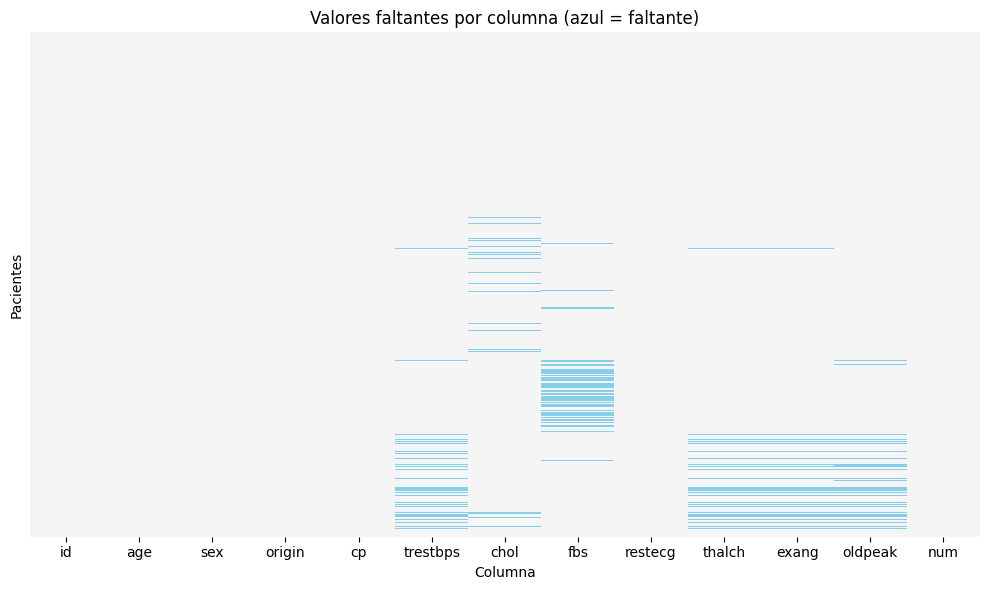

In [102]:
plt.figure(figsize=(10, 6))
sns.heatmap(cardio_df.isna(), cbar=False, cmap=['whitesmoke', 'skyblue'], yticklabels=False)
plt.title('Valores faltantes por columna (azul = faltante)')
plt.xlabel('Columna')
plt.ylabel('Pacientes')
plt.tight_layout()
plt.show()

**Respuesta:** Se eliminaron las columnas `ca` (66.34% de faltantes), `thal` (52.72%) y `slope` (33.55%) por superar el 30%. Las variables restantes con faltantes son fbs (9.69%), oldpeak (6.75%), trestbps (6.43%), thalch (5.99%), exang (5.99%) y chol (3.27%).

En el mapa de calor se observa que **`trestbps`, `thalch`, `exang` y `oldpeak`** presentan valores faltantes de manera simultánea en el mismo grupo de pacientes (filas azules que atraviesan las cuatro columnas a la misma altura). `thalch` y `exang` faltan exactamente en los mismos 55 registros, y `oldpeak` y `trestbps` coinciden en casi todos ellos. En cambio, los faltantes de `chol` y `fbs` aparecen en filas distintas, sin relación con las demás variables.

Esta concurrencia **tiene sentido desde el punto de vista clínico**: `thalch` (frecuencia cardíaca máxima), `exang` (angina inducida por ejercicio) y `oldpeak` (depresión del segmento ST inducida por ejercicio) se obtienen de la misma **prueba de esfuerzo**. Si a un paciente no se le realizó esta prueba, o no se registraron sus resultados, es esperable que falten las tres variables a la vez. `trestbps`, que se mide al inicio de la evaluación, también falta en esos pacientes, lo que sugiere que su registro clínico se capturó de forma incompleta. Además, 53 de esos 55 pacientes provienen del mismo lugar de estudio (VA Long Beach), lo que indica que los faltantes podrían deberse a diferencias en los protocolos de registro de ese hospital.

5. Si centramos el análisis en una de las variables identificadas en el ejercicio anterior, se puede suponer que los hallazgos obtenidos podrían ser aplicables a las demás variables que presentan un patrón similar.

* ¿Tendrán los valores faltantes de `thalch` relación con alguna otra variable? Analízalo considerando las siguientes columnas:
  *   Numéricas: `age`, `chol`
  *   Categóricas: `restecg`, `cp`

Para ello deberás dividir cada columna en dos grupos: con / sin faltantes en `thalch` y utilizar métodos gráficos y pruebas de hipótesis para ver si hay diferencias significativas.
* Incluye las conclusiones del análisis con los resultados obtenidos.
* Justifica si el mecanismo de faltantes de `thalch` es MCAR (*Missing Completely at Random*) o MAR (*Missing at Random*).

**NOTA**. Puedes reutilizar las funciones `Diagnose_MV_Numerical` y `Diagnose_MV_Categorical` definidas en Hands-On-Prep_Missing_Values.zip. Revisa nuevamente cómo utilizarlas.

In [103]:
from scipy.stats import ttest_ind
def Diagnose_MV_Numerical(df,str_att_name,BM_MV):
    MV_labels = {True:'With Missing Values',False:'Without Missing Values'}

    labels=[]
    box_sr = pd.Series('',index = BM_MV.unique())
    for poss in BM_MV.unique():
        BM = BM_MV == poss
        box_sr[poss] = df[BM][str_att_name].dropna()
        labels.append(MV_labels[poss])

    plt.boxplot(box_sr,vert=False)
    plt.yticks([1,2],labels)
    plt.xlabel(str_att_name)
    plt.show()

    plt.figure(figsize=(10,4))

    att_range = (df[str_att_name].min(),df[str_att_name].max())

    for i,poss in enumerate(BM_MV.unique()):
        plt.subplot(1,2,i+1)
        BM = BM_MV == poss
        df[BM][str_att_name].hist()
        plt.xlim = att_range
        plt.xlabel(str_att_name)
        plt.title(MV_labels[poss])

    plt.show()

    group_1_data = df[BM_MV][str_att_name].dropna()
    group_2_data = df[~BM_MV][str_att_name].dropna()

    p_value = ttest_ind(group_1_data,group_2_data).pvalue

    print('p-value of t-test: {}'.format(p_value))

In [104]:
from scipy.stats import chi2_contingency
def Diagnose_MV_Categorical(df,str_att_name,BM_MV):
    MV_labels = {True:'With Missing Values',False:'Without Missing Values'}

    plt.figure(figsize=(10,4))
    for i,poss in enumerate(BM_MV.unique()):
        plt.subplot(1,2,i+1)
        BM = BM_MV == poss
        df[BM][str_att_name].value_counts().plot.bar()
        plt.title(MV_labels[poss])
    plt.show()

    contigency_table = pd.crosstab(BM_MV,df[str_att_name])
    p_value = chi2_contingency(contigency_table)[1]

    print('p-value of Chi_squared test: {}'.format(p_value))

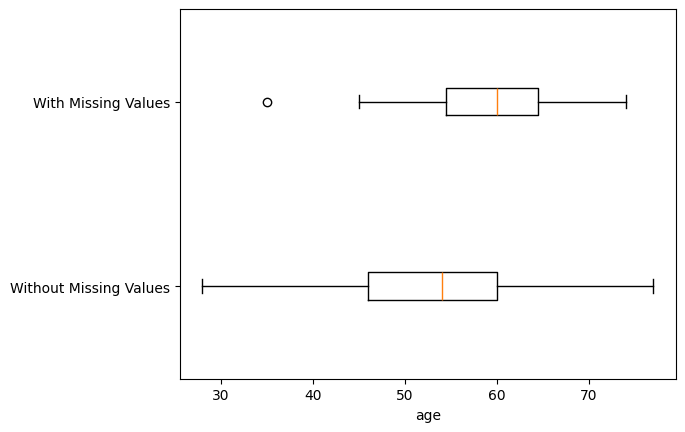

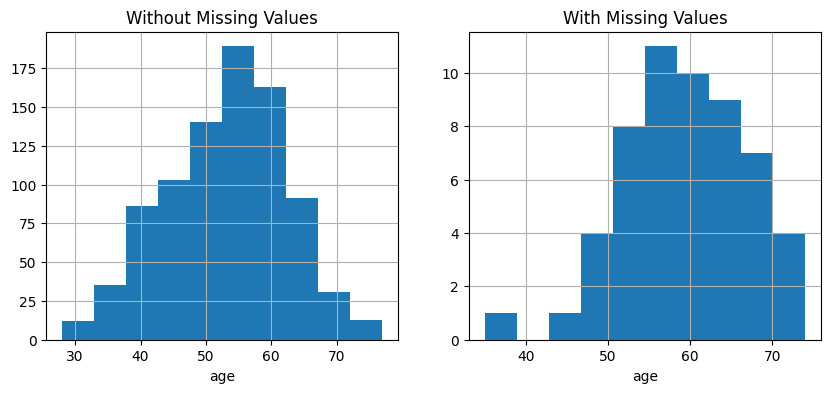

p-value of t-test: 1.5041244185890902e-06


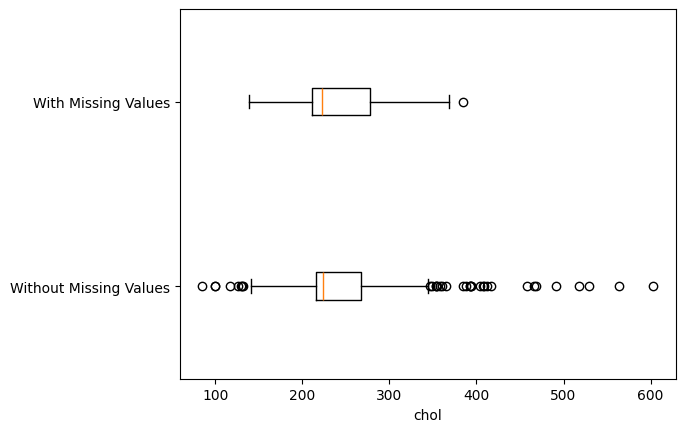

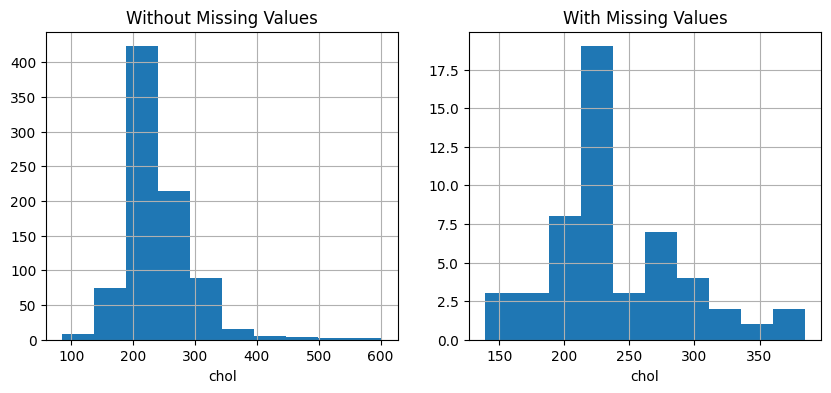

p-value of t-test: 0.7165289974295672


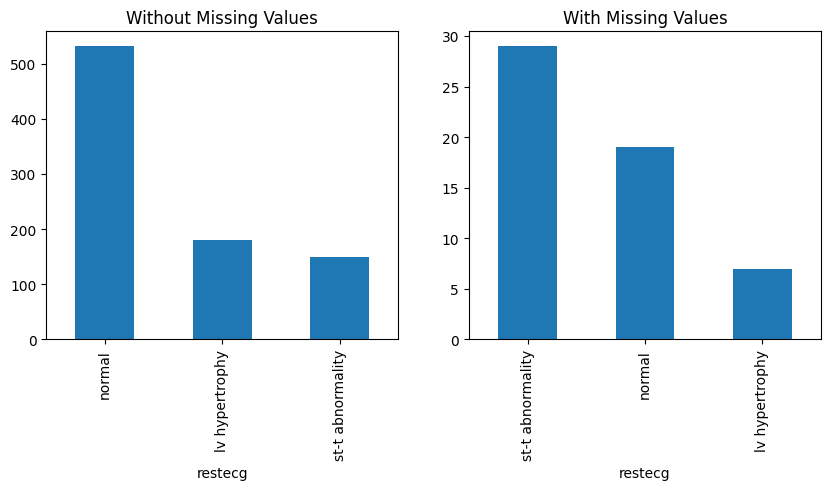

p-value of Chi_squared test: 1.1472889573985467e-09


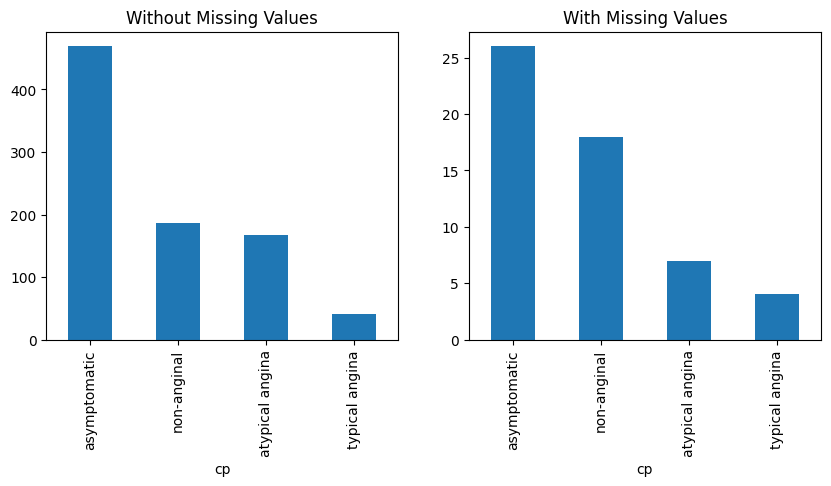

p-value of Chi_squared test: 0.15420097177251701


In [105]:
BM_MV = cardio_df['thalch'].isna()
Diagnose_MV_Numerical(cardio_df, 'age', BM_MV)
Diagnose_MV_Numerical(cardio_df, 'chol', BM_MV)
Diagnose_MV_Categorical(cardio_df, 'restecg', BM_MV)
Diagnose_MV_Categorical(cardio_df, 'cp', BM_MV)

**Respuesta:** Para determinar si los valores faltantes de `thalch` se relacionan con otras variables, se dividió a los pacientes en dos grupos (con y sin faltantes en `thalch`) y se compararon mediante gráficos y pruebas de hipótesis, con un nivel de significancia de 0.05:

| Variable | Prueba | p-value | Resultado |
|---|---|---|---|
| age | t de Student | 1.5 × 10⁻⁶ | Diferencia significativa |
| chol | t de Student | 0.717 | Sin diferencia significativa |
| restecg | Chi-cuadrada | 1.1 × 10⁻⁹ | Diferencia significativa |
| cp | Chi-cuadrada | 0.154 | Sin diferencia significativa |

**Conclusiones:**

* **age:** los pacientes sin registro de `thalch` son mayores (mediana cercana a 60 años frente a 54), como se observa en el boxplot y los histogramas. La diferencia es estadísticamente significativa.
* **restecg:** la distribución cambia notablemente entre grupos. En los pacientes sin `thalch`, la categoría más frecuente es *st-t abnormality* (29 de 55, el 53%), mientras que en los pacientes con registro predomina *normal* y *st-t abnormality* representa solo el 17%. La diferencia es estadísticamente significativa.
* **chol** y **cp:** sus distribuciones son similares en ambos grupos y las pruebas no muestran diferencias significativas.

**Mecanismo de faltantes:** el mecanismo de `thalch` es **MAR (Missing at Random)** y no MCAR. Si fuera MCAR, los pacientes con y sin el dato no deberían diferir en ninguna variable; sin embargo, presentan diferencias significativas en `age` y `restecg`, variables que sí están observadas. Esto tiene sentido clínico: es más probable que a pacientes de mayor edad o con alteraciones en el electrocardiograma en reposo no se les realice la prueba de esfuerzo, por el riesgo que implica. Dado que `trestbps`, `exang` y `oldpeak` comparten el mismo patrón de faltantes (ejercicio 4), esta conclusión puede extenderse a ellas. En consecuencia, la imputación de estas variables debe considerar las variables relacionadas, como se hará en el siguiente ejercicio al imputar por grupos de `restecg`.

6. La imputación de una variable con valores faltantes puede realizarse por grupos o segmentos relevantes. Esto significa que, en lugar de utilizar una estadística global de toda la columna, se calcula la estadística correspondiente dentro de cada grupo definido por otra variable, haciendo:

> `df['var_with_missing'] = df.groupby('related_var')['var_with_missing'].transform(lambda x: x.fillna(x.median()))`

* Utiliza la variable `restecg` para separar los grupos e imputar `thalch` y todas las variables con patrón de faltantes similar (identificadas en el ejercicio 4) Asegúrate de cambiar la función de agregado si hay variables no numéricas.
* Vuelve a generar el mapa de calor para verificar que los valores faltantes en estas variables hayan sido imputados.

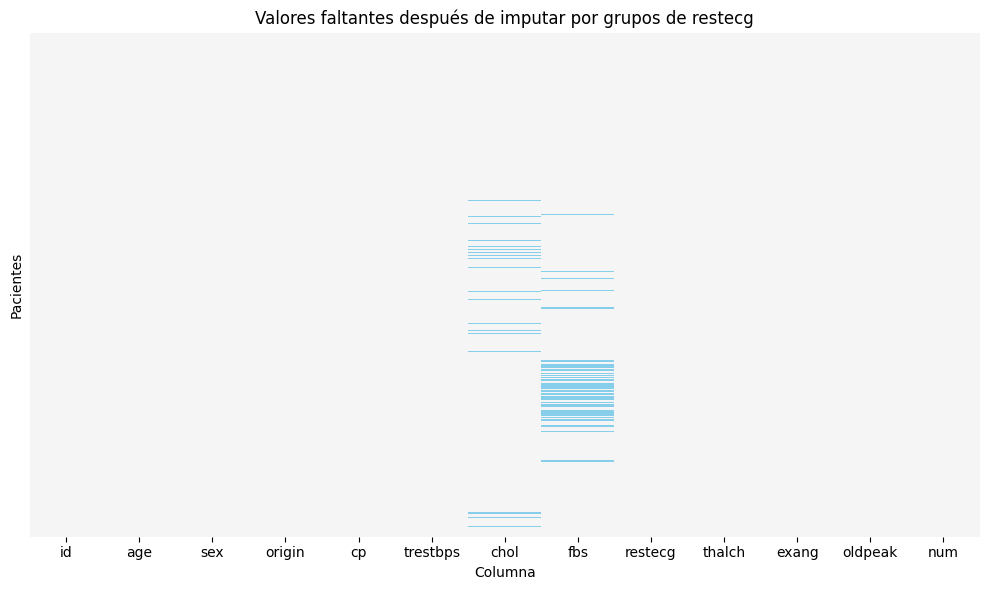

In [106]:
pd.set_option('future.no_silent_downcasting', True)
for col in ['thalch', 'trestbps', 'oldpeak']:
    cardio_df[col] = cardio_df.groupby('restecg')[col].transform(lambda x: x.fillna(x.median()))
cardio_df['exang'] = cardio_df.groupby('restecg')['exang'].transform(lambda x: x.fillna(x.mode()[0]))

plt.figure(figsize=(10, 6))
sns.heatmap(cardio_df.isna(), cbar=False, cmap=['whitesmoke', 'skyblue'], yticklabels=False)
plt.title('Valores faltantes después de imputar por grupos de restecg')
plt.xlabel('Columna')
plt.ylabel('Pacientes')
plt.tight_layout()
plt.show()

**Respuesta:** Se imputaron las variables con el patrón de faltantes identificado en el ejercicio 4 (`thalch`, `trestbps`, `oldpeak` y `exang`), utilizando `restecg` para formar los grupos. Dado que en el ejercicio 5 se encontró que los faltantes se relacionan con esta variable (mecanismo MAR), imputar por grupos permite asignar a cada paciente un valor representativo de pacientes con un resultado de electrocardiograma similar, en lugar de un valor general de toda la columna.

* Para las variables numéricas (`thalch`, `trestbps` y `oldpeak`) se utilizó la **mediana** de cada grupo, por ser una medida robusta ante valores atípicos y asimetría.
* Para `exang`, al ser una variable no numérica (Verdadero / Falso), se cambió la función de agregado a la **moda** (el valor más frecuente) de cada grupo.

El mapa de calor confirma que estas cuatro variables ya no presentan valores faltantes. Solo quedan faltantes en `chol` y `fbs`, que no comparten este patrón y se imputarán en el siguiente ejercicio.

7. Para las variables que aún presentan valores faltantes, realiza la imputación utilizando estadísticas generales calculadas sobre toda la columna, sin segmentar por grupos. Esta vez utiliza la clase `SimpleImputer` de sklearn
* Justifica la estrategia (*mean, median, most_frequent*) que emplees en cada caso.


In [107]:
imp_mediana = SimpleImputer(strategy='median')
cardio_df[['chol']] = imp_mediana.fit_transform(cardio_df[['chol']])

imp_moda = SimpleImputer(strategy='most_frequent')
cardio_df[['fbs']] = imp_moda.fit_transform(cardio_df[['fbs']])

print(imp_mediana.statistics_, imp_moda.statistics_)
cardio_df.isna().sum()

[223.] [False]


,0
id,0
age,0
sex,0
origin,0
cp,0
trestbps,0
chol,0
fbs,0
restecg,0
thalch,0


**Respuesta:** Las variables que aún tenían valores faltantes eran `chol` y `fbs`, que no compartían el patrón de faltantes de la prueba de esfuerzo. Se imputaron con `SimpleImputer` utilizando una estadística calculada sobre toda la columna:

* **`chol` → `median` (valor imputado: 223 mg/dl).** Es una variable numérica con asimetría positiva fuerte (1.64) y valores extremos de hasta 603 mg/dl (ejercicio 3). La media se ve afectada por esos valores extremos, mientras que la mediana es robusta y representa mejor al paciente típico. La estrategia `mean` solo sería adecuada para una variable numérica simétrica y sin valores atípicos.
* **`fbs` → `most_frequent` (valor imputado: False).** Es una variable categórica binaria (glucosa en ayunas mayor a 120 mg/dl: Verdadero / Falso), por lo que no admite media ni mediana; la única estrategia aplicable es la moda, es decir, el valor más frecuente.

Tras la imputación, el conteo de valores faltantes es 0 en todas las columnas.

8. Dibuja boxplots de todas las variables numéricas.
* Obtén los valores atípicos mediante el método gráfico, a partir del objeto devuelto por el boxplot.

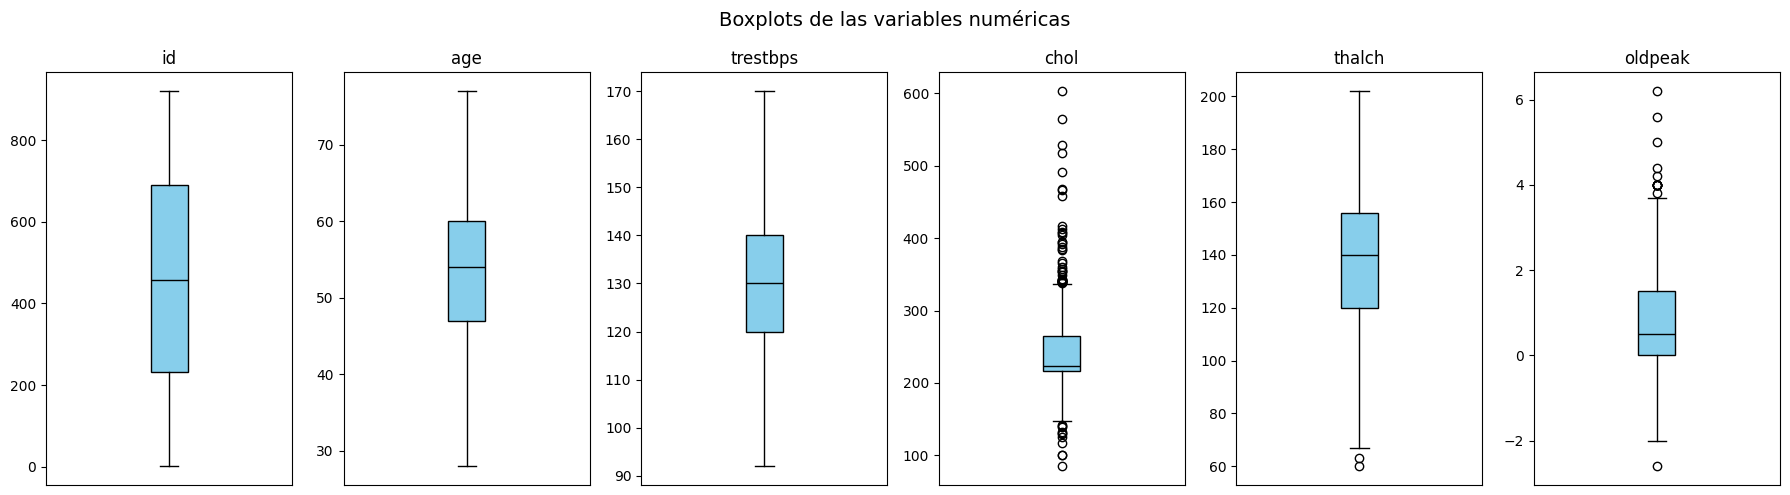

id 0 []
age 0 []
trestbps 0 []
chol 50 [85.0, 100.0, 100.0, 117.0, 126.0, 129.0, 131.0, 132.0, 139.0, 141.0, 142.0, 338.0, 339.0, 339.0, 340.0, 340.0, 341.0, 341.0, 341.0, 342.0, 342.0, 342.0, 344.0, 349.0, 353.0, 354.0, 355.0, 358.0, 360.0, 365.0, 369.0, 384.0, 385.0, 388.0, 392.0, 394.0, 394.0, 404.0, 407.0, 409.0, 412.0, 417.0, 458.0, 466.0, 468.0, 491.0, 518.0, 529.0, 564.0, 603.0]
thalch 2 [60.0, 63.0]
oldpeak 14 [-2.6, 3.8, 4.0, 4.0, 4.0, 4.0, 4.0, 4.0, 4.0, 4.2, 4.4, 5.0, 5.6, 6.2]


In [109]:
num_cols = cardio_df.select_dtypes(include='number').columns.tolist()
fig, axes = plt.subplots(1, len(num_cols), figsize=(18, 5))
atipicos = {}
for ax, col in zip(axes, num_cols):
    bp = ax.boxplot(cardio_df[col], patch_artist=True,
                    boxprops={'facecolor': 'skyblue'}, medianprops={'color': 'black'})
    ax.set_title(col)
    ax.set_xticks([])
    atipicos[col] = sorted(bp['fliers'][0].get_ydata().tolist())
fig.suptitle('Boxplots de las variables numéricas', fontsize=14)
plt.tight_layout()
plt.show()

for col, valores in atipicos.items():
    print(col, len(valores), valores)

**Respuesta:** Los valores atípicos se obtuvieron del objeto devuelto por `boxplot()`, a partir de su elemento `fliers` (los puntos que quedan fuera de los bigotes):

* **age:** 0 valores atípicos; todas las edades (28 a 77 años) quedan dentro de los bigotes.
* **trestbps:** 27 valores atípicos: uno bajo (80 mm Hg) y 26 altos (entre 172 y 200 mm Hg).
* **chol:** 44 valores atípicos, en ambos extremos: valores bajos (85 a 142 mg/dl) y altos (342 a 603 mg/dl). Es la variable con más atípicos, lo cual coincide con su alta curtosis (6.57) observada en el ejercicio 3. Además, la imputación con la mediana concentró más valores en el centro, estrechando la caja.
* **thalch:** 2 valores atípicos bajos (60 y 63 latidos por minuto).


9. Para la variable `trestbps`, calcula los valores atípicos utilizando el método del rango intercuartílico (IQR).
* Para ello obtén los cuartiles necesarios y determina los límites superior e inferior para filtrar los valores que se encuentren fuera de ese rango.
* Verifica si los resultados coinciden con los obtenidos en el ejercicio anterior.

In [93]:
q1 = cardio_df['trestbps'].quantile(0.25)
q3 = cardio_df['trestbps'].quantile(0.75)
iqr = q3 - q1
lim_inf = q1 - 1.5 * iqr
lim_sup = q3 + 1.5 * iqr
print('Q1:', q1, '| Q3:', q3, '| IQR:', iqr)
print('Límite inferior:', lim_inf, '| Límite superior:', lim_sup)

atipicos_iqr = sorted(cardio_df.loc[(cardio_df['trestbps'] < lim_inf) | (cardio_df['trestbps'] > lim_sup), 'trestbps'].tolist())
print('Atípicos IQR:', len(atipicos_iqr), atipicos_iqr)
print('¿Coinciden con el boxplot?', atipicos_iqr == atipicos['trestbps'])

Q1: 120.0 | Q3: 140.0 | IQR: 20.0
Límite inferior: 90.0 | Límite superior: 170.0
Atípicos IQR: 27 [80.0, 172.0, 172.0, 174.0, 178.0, 178.0, 178.0, 180.0, 180.0, 180.0, 180.0, 180.0, 180.0, 180.0, 180.0, 180.0, 180.0, 180.0, 180.0, 185.0, 190.0, 190.0, 192.0, 200.0, 200.0, 200.0, 200.0]
¿Coinciden con el boxplot? False


**Respuesta:** Para `trestbps` se obtuvieron los cuartiles Q1 = 120 y Q3 = 140, por lo que el rango intercuartílico es IQR = Q3 − Q1 = 20 mm Hg. Con ellos se calcularon los límites:

* **Límite inferior** = Q1 − 1.5 × IQR = 120 − 30 = **90 mm Hg**
* **Límite superior** = Q3 + 1.5 × IQR = 140 + 30 = **170 mm Hg**

Se identificaron **27 valores atípicos**: uno por debajo del límite inferior (80 mm Hg) y 26 por encima del superior (entre 172 y 200 mm Hg).

Los resultados **coinciden exactamente** con los obtenidos mediante el método gráfico en el ejercicio anterior (la comparación devuelve `True`). Esto se debe a que el boxplot utiliza internamente el mismo criterio: sus bigotes se extienden hasta 1.5 veces el IQR desde los cuartiles, y los puntos fuera de ese rango se dibujan como atípicos.

10. Elimina los valores atípicos identificados de la variable `trestbps`.
* Dibuja el boxplot final para visualizar la distribución depurada.

Registros antes: 891
Registros después: 891


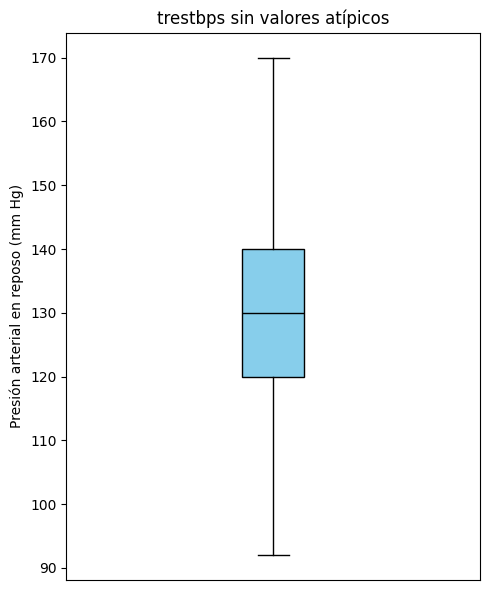

In [110]:
print('Registros antes:', len(cardio_df))
cardio_df = cardio_df[(cardio_df['trestbps'] >= lim_inf) & (cardio_df['trestbps'] <= lim_sup)]
print('Registros después:', len(cardio_df))

plt.figure(figsize=(5, 6))
plt.boxplot(cardio_df['trestbps'], patch_artist=True,
            boxprops={'facecolor': 'skyblue'}, medianprops={'color': 'black'})
plt.title('trestbps sin valores atípicos')
plt.ylabel('Presión arterial en reposo (mm Hg)')
plt.xticks([])
plt.tight_layout()
plt.show()

**Respuesta:** Se eliminaron los 27 registros cuyo valor de `trestbps` se encontraba fuera de los límites calculados con el método IQR (menor a 90 o mayor a 170 mm Hg). El dataframe pasó de 918 a 891 registros, lo que representa una eliminación del 2.9% de los datos.

El boxplot final muestra la distribución depurada de `trestbps`: ya no presenta valores atípicos y todos los valores se encuentran entre 92 y 170 mm Hg (el límite inferior calculado era 90, pero el valor más bajo registrado dentro del rango es 92), con la mediana en 130 mm Hg.

---

**Declaración de uso de IA**

Anthropic. (2026). *Claude (Opus 5.5)* [Modelo de lenguaje grande]  utilizado como tutor paso a paso: imputación, pruebas de hipótesis y detección de valores atípicos; depuración de errores y warnings, y apoyo en la redacción e interpretación de resultados. El código fue ejecutado y verificado por mi. https://claude.ai/

---